In [1]:
%pip install -q numpy pandas matplotlib scikit-learn seaborn yfinance tensorflow python-dateutil

Note: you may need to restart the kernel to use updated packages.


#### Импорт библиотек и подготовка датасета

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from datetime import datetime
from dateutil.relativedelta import relativedelta

sns.set_style('whitegrid')
plt.style.use('fivethirtyeight')

tech_list = ['AAPL', 'GOOG', 'MSFT', 'AMZN']
company_name = ['APPLE', 'GOOGLE', 'MICROSOFT', 'AMAZON']

In [4]:
name_by_ticker = dict(zip(tech_list, company_name))
end = datetime.now()
start = end - relativedelta(years=2)

companies = {}
for ticker in tech_list:
    try:
        company = yf.download(ticker, start=start, end=end,
                              auto_adjust=False, progress=False,
                              multi_level_index=False)
        if isinstance(company.columns, pd.MultiIndex):
            company.columns = company.columns.get_level_values(0)
        if company.empty:
            print(f'Нет данных для {ticker}')
            continue
        company = company.copy().sort_index()
        company['company_name'] = name_by_ticker[ticker]
        company['ticker'] = ticker
        companies[ticker] = company
    except Exception as exc:
        print(f'Не удалось загрузить {ticker} : {exc}')

/opt/homebrew/lib/python3.11/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/opt/homebrew/lib/python3.11/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/opt/homebrew/lib/python3.11/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.sort_index(inplace=True)
/opt/homebrew/lib/pyth

In [5]:
company_list = list(companies.values())
df = pd.concat(company_list, axis=0).sort_index()
print('Загружено:', ', '.join(companies))

Загружено: AAPL, GOOG, MSFT, AMZN


In [6]:
df.head()

,Adj Close,Close,High,Low,Open,Volume,company_name,ticker
Date,,,,,,,,
2024-10-23,228.845657,230.759995,235.139999,227.759995,234.080002,52287000,APPLE,AAPL
2024-10-23,184.710007,184.710007,189.160004,183.690002,188.850006,31937100,AMAZON,AMZN
2024-10-23,417.996918,424.600006,431.079987,422.529999,430.859985,19654400,MICROSOFT,MSFT
2024-10-23,163.336853,164.479996,167.600006,163.632996,166.429993,12754300,GOOGLE,GOOG
2024-10-24,418.124878,424.730011,425.980011,422.399994,425.329987,13581600,MICROSOFT,MSFT


In [7]:
df.tail()

,Adj Close,Close,High,Low,Open,Volume,company_name,ticker
Date,,,,,,,,
2026-10-21,343.989990,343.989990,345.250000,338.829987,339.359985,35614100,APPLE,AAPL
2026-10-22,320.760010,320.760010,327.700012,318.450012,326.765015,21044600,GOOGLE,GOOG
2026-10-22,348.220001,348.220001,348.359985,342.279999,344.940002,46718600,APPLE,AAPL
2026-10-22,521.080017,521.080017,533.599976,520.299988,533.140015,21104500,MICROSOFT,MSFT
2026-10-22,250.380005,250.380005,258.410004,248.000000,258.179993,48658900,AMAZON,AMZN


#### Описательная статистика

In [8]:
companies['AAPL'].describe() if 'AAPL' in companies else print('Данные не загружены')

,Adj Close,Close,High,Low,Open,Volume
count,501.000000,501.000000,501.000000,501.000000,501.000000,5.010000e+02
mean,256.770904,257.612115,260.228883,254.755728,257.286986,5.099271e+07
std,40.652559,40.251547,40.435600,39.941489,40.127021,2.256090e+07
min,171.365982,172.419998,190.339996,169.210007,171.949997,1.791060e+07
25%,226.323975,227.630005,229.830002,225.369995,226.880005,3.874310e+07
50%,253.493607,254.490005,256.329987,251.710007,254.559998,4.573080e+07
75%,278.023254,278.779999,280.910004,276.500000,278.160004,5.457510e+07
max,348.220001,348.220001,348.359985,342.279999,346.950012,2.617755e+08


In [9]:
companies['AAPL'].info() if 'AAPL' in companies else print('Данные не загружены')

<class 'pandas.DataFrame'>
DatetimeIndex: 501 entries, 2024-10-23 to 2026-10-22
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Adj Close     501 non-null    float64
 1   Close         501 non-null    float64
 2   High          501 non-null    float64
 3   Low           501 non-null    float64
 4   Open          501 non-null    float64
 5   Volume        501 non-null    int64  
 6   company_name  501 non-null    str    
 7   ticker        501 non-null    str    
dtypes: float64(5), int64(1), str(2)
memory usage: 35.2 KB


#### Данные на момент закрытия биржи

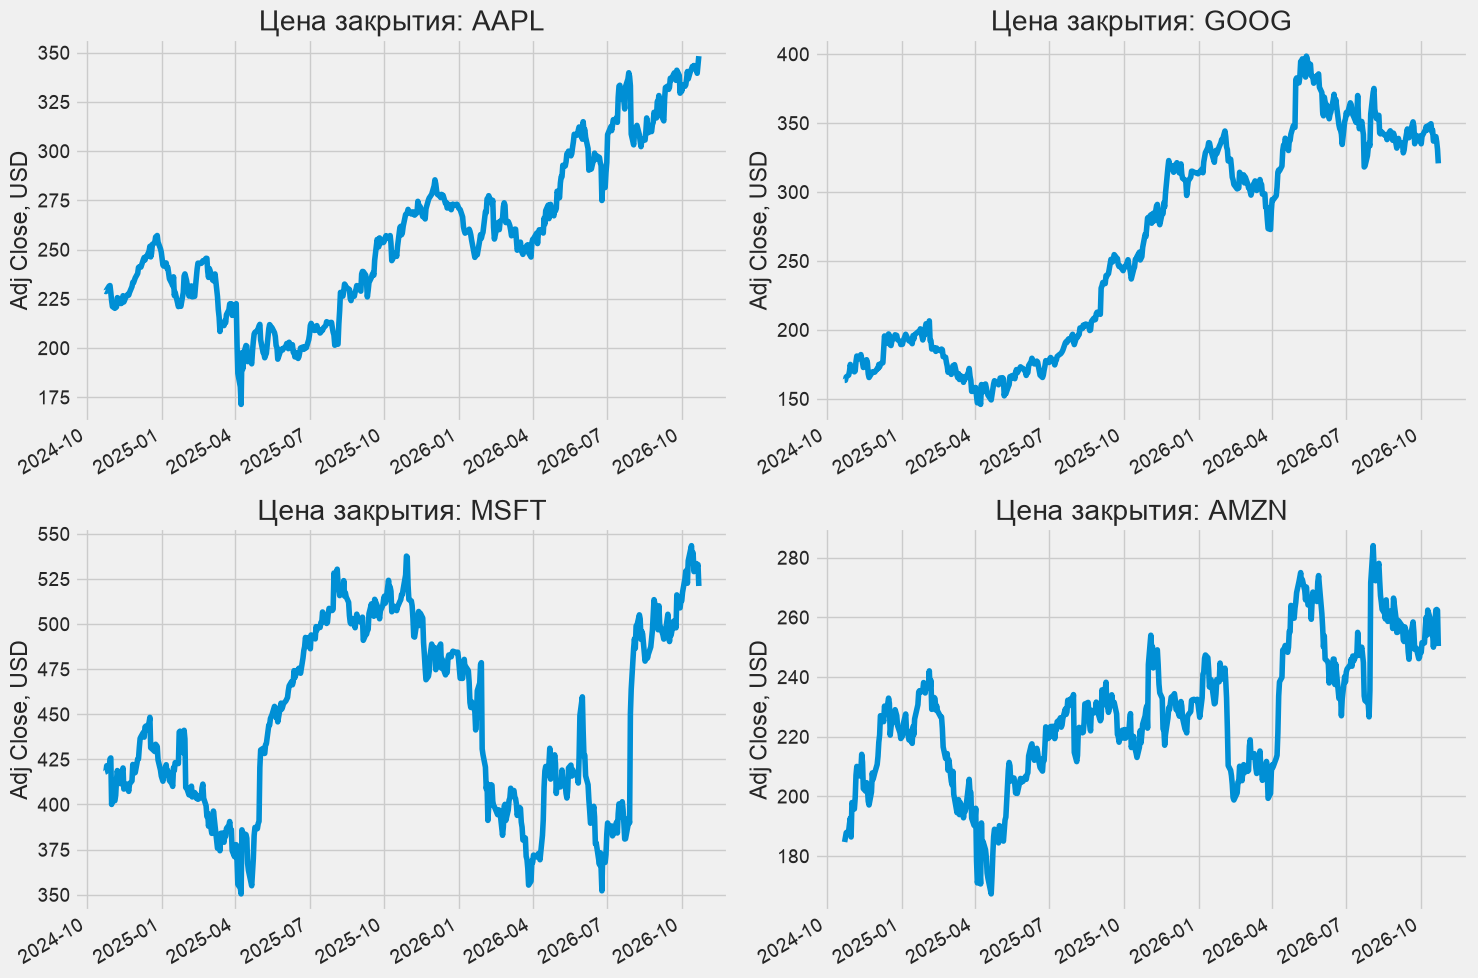

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, ticker in zip(axes.flat, tech_list):
    if ticker in companies:
        companies[ticker]['Adj Close'].plot(ax=ax)
    ax.set(title=f'Цена закрытия: {ticker}', xlabel='', ylabel='Adj Close, USD')
plt.tight_layout()
plt.show()

#### Данные об объёме торгов

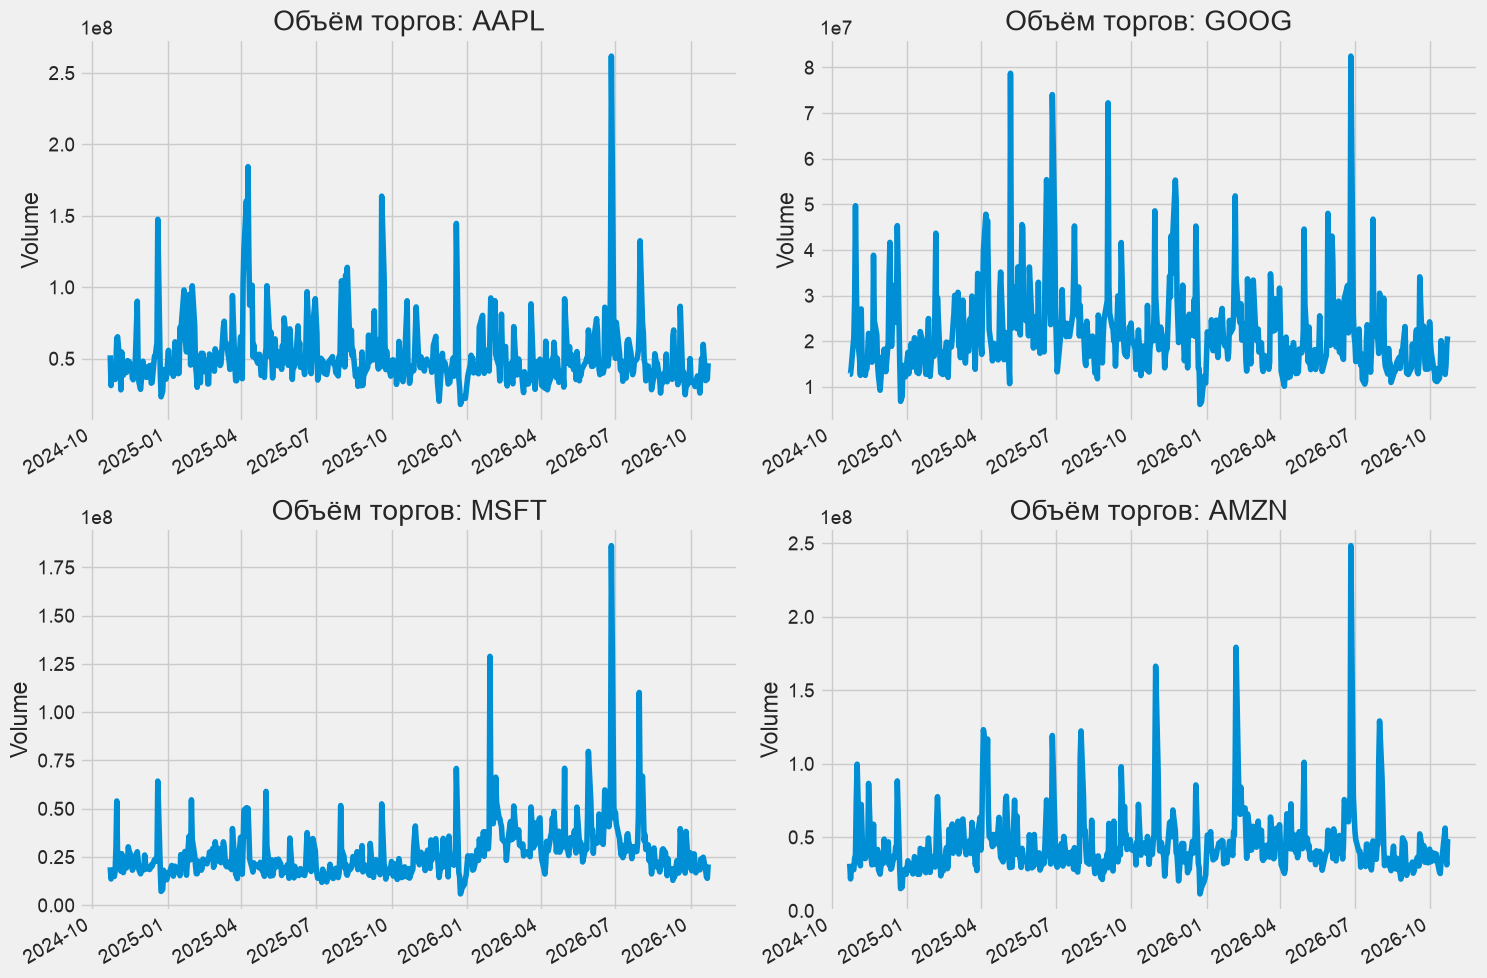

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, ticker in zip(axes.flat, tech_list):
    if ticker in companies:
        companies[ticker]['Volume'].plot(ax=ax)
    ax.set(title=f'Объём торгов: {ticker}', xlabel='', ylabel='Volume')
plt.tight_layout()
plt.show()

#### Модель MA (moving average) скользящее среднее

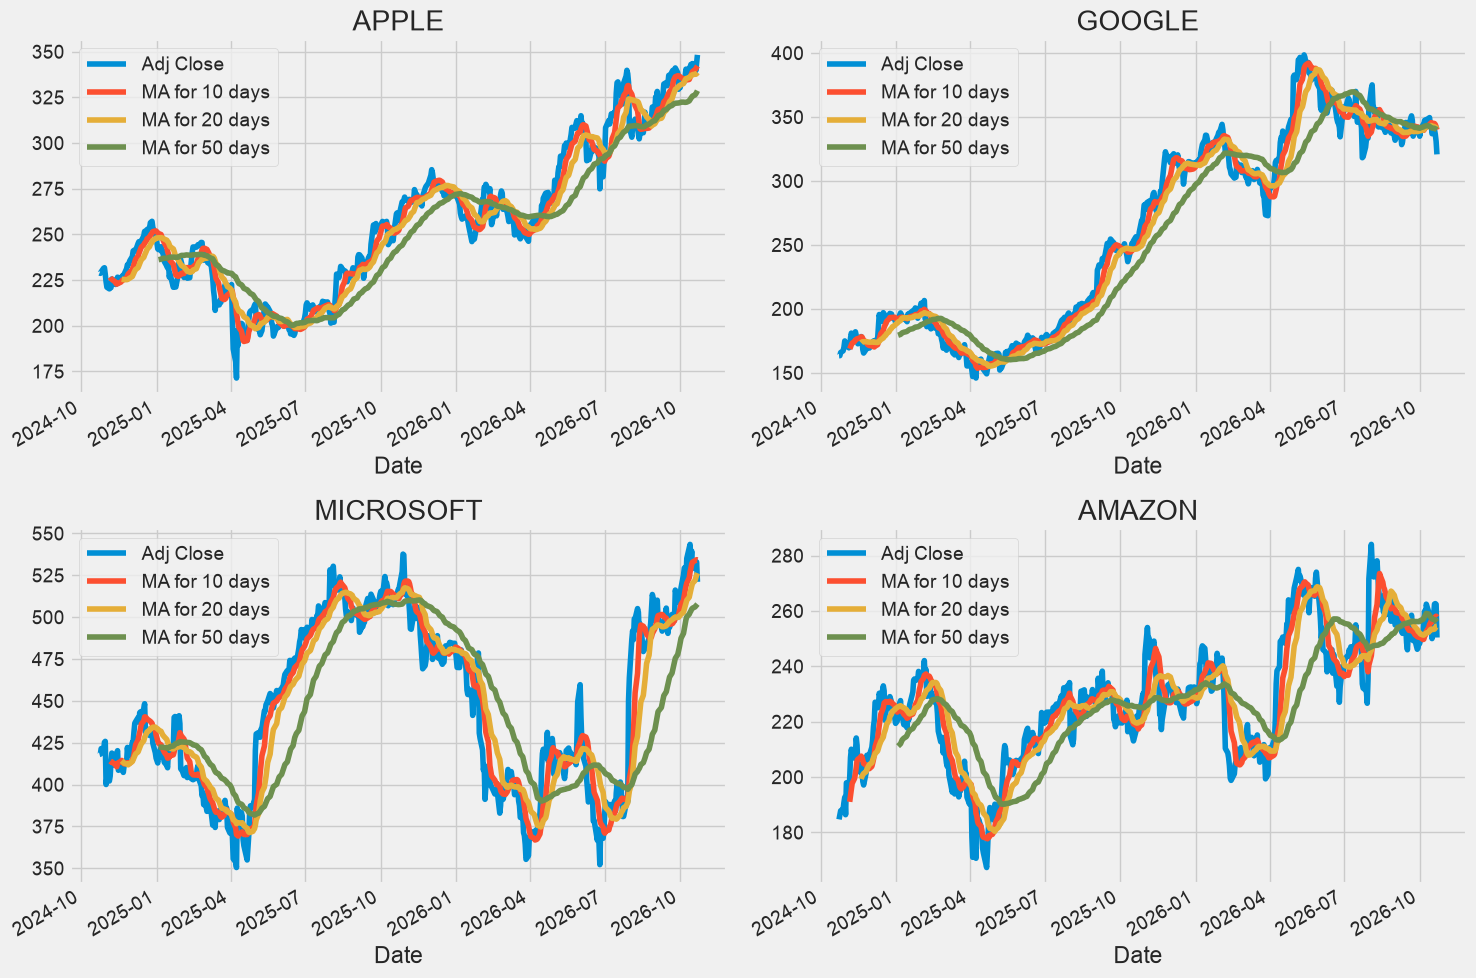

In [12]:
ma_day = [10, 20, 50]
for ticker, company in companies.items():
    for ma in ma_day:
        company[f'MA for {ma} days'] = company['Adj Close'].rolling(window=ma).mean()


fig, axes = plt.subplots(2, 2, figsize=(15, 10))
cols = ['Adj Close'] + [f'MA for {ma} days' for ma in ma_day]
for ax, ticker in zip(axes.flat, tech_list):
    if ticker in companies:
        companies[ticker][cols].plot(ax=ax)
    ax.set_title(name_by_ticker[ticker])
plt.tight_layout()
plt.show()

#### Дневные изменения

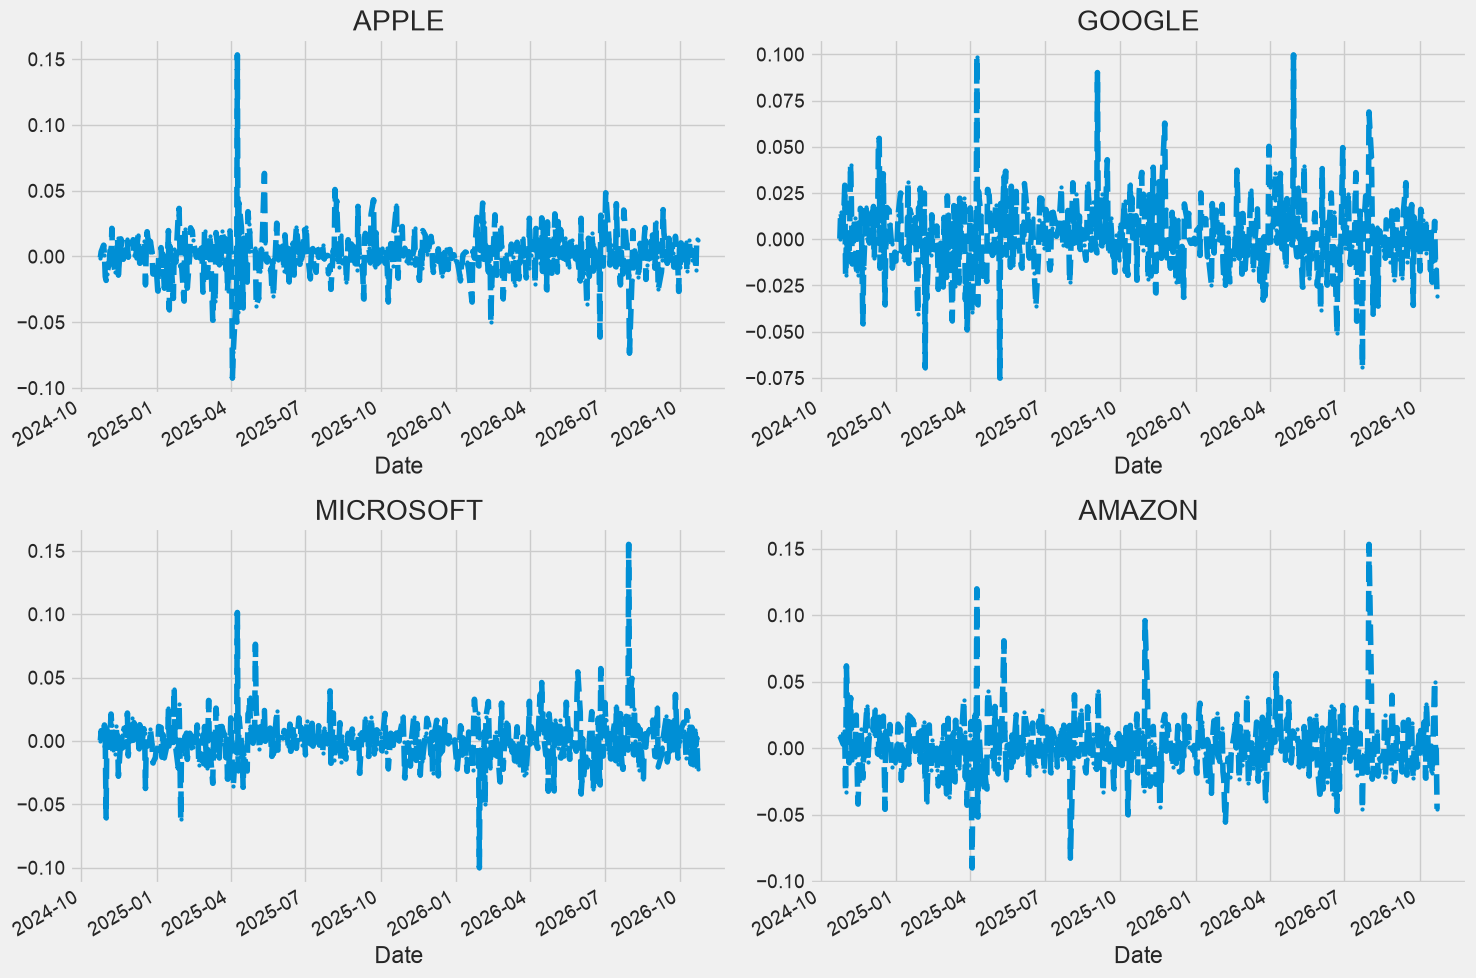

In [14]:
for company in companies.values():
    company['Daily Return'] = company['Adj Close'].pct_change()


fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, ticker in zip(axes.flat, tech_list):
    if ticker in companies:
        companies[ticker]['Daily Return'].plot(ax=ax, linestyle='--', marker='o', markersize=2)
    ax.set_title(name_by_ticker[ticker])
plt.tight_layout()
plt.show()

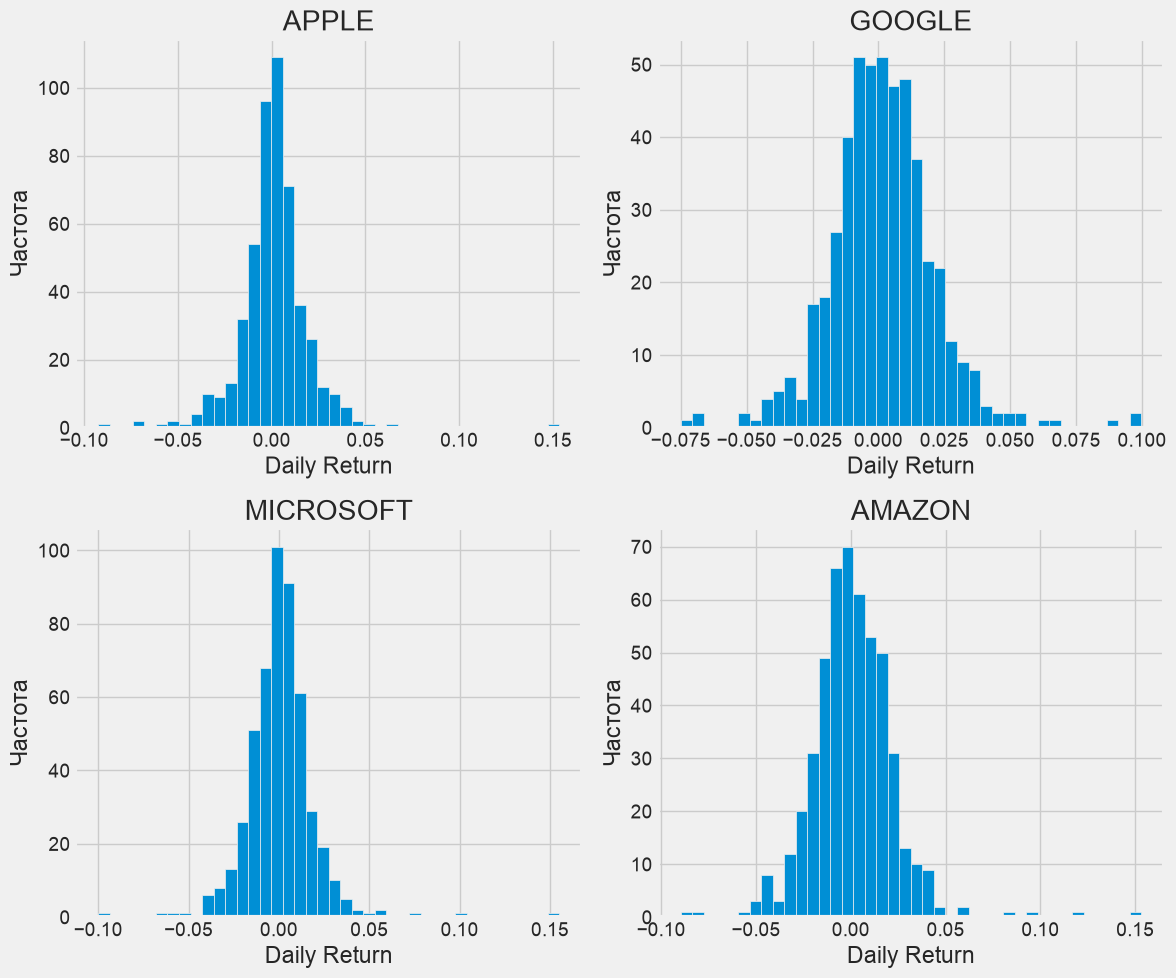

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
cols = ['Adj Close'] + [f'MA for {ma} days' for ma in ma_day]
for ax, ticker in zip(axes.flat, tech_list):
    if ticker in companies:
        companies[ticker]['Daily Return'].dropna().hist(bins=40, ax=ax)
    ax.set(xlabel='Daily Return', ylabel='Частота', title=name_by_ticker[ticker])
plt.tight_layout()
plt.show()

#### Корреляция стоимости акций

In [20]:
closing_df = pd.concat(
    {ticker: company['Adj Close'] for ticker, company in companies.items()},
    axis=1
).sort_index()

tech_rets = closing_df.pct_change(fill_method=None).dropna(how='all')
tech_rets.head(10)

,AAPL,GOOG,MSFT,AMZN
Date,,,,
2024-10-24,-0.000823,0.000304,0.000306,0.009041
2024-10-25,0.003643,0.014952,0.008052,0.007780
2024-10-28,0.008600,0.008084,-0.003644,0.002981
2024-10-29,0.001157,0.016633,0.012565,0.012952
2024-10-30,-0.015278,0.029216,0.001343,0.009956
2024-10-31,-0.018209,-0.019587,-0.060528,-0.032844
2024-11-01,-0.013280,-0.000232,0.009893,0.061856
2024-11-04,-0.004038,-0.011410,-0.004654,-0.010862
2024-11-05,0.006486,0.004277,0.007345,0.019001


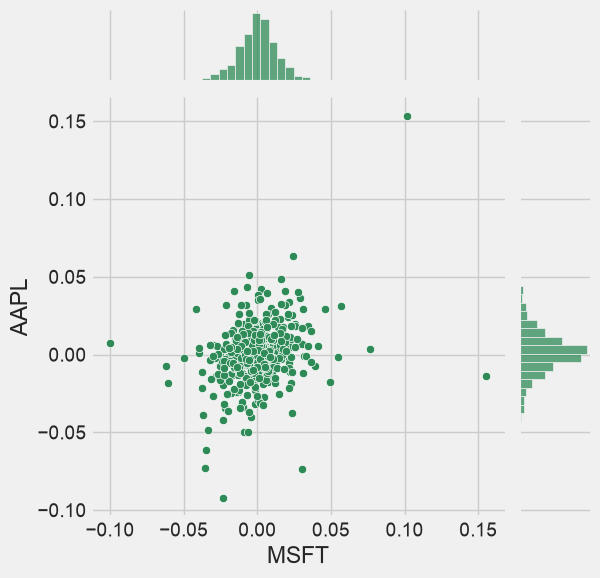

In [22]:
sns.jointplot(x='MSFT', y='AAPL', data=tech_rets, kind='scatter', color='seagreen')
plt.show()

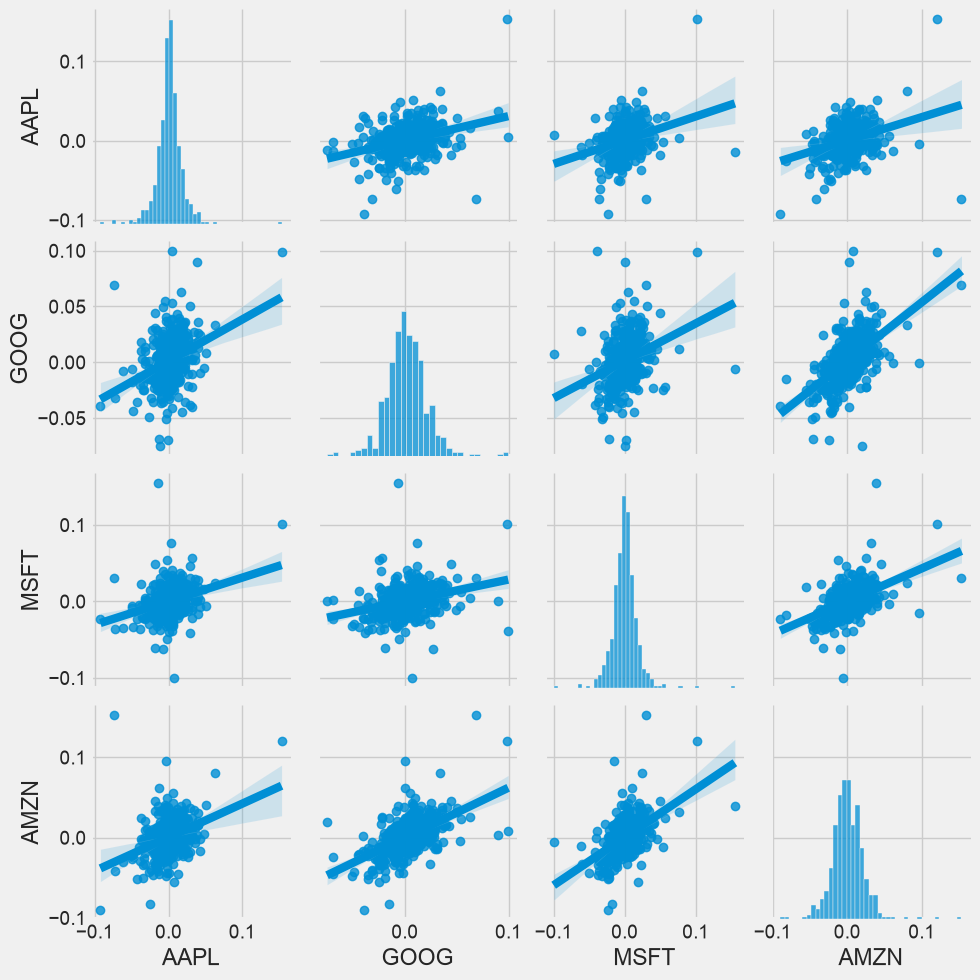

In [25]:
sns.pairplot(tech_rets, kind='reg')
plt.show()

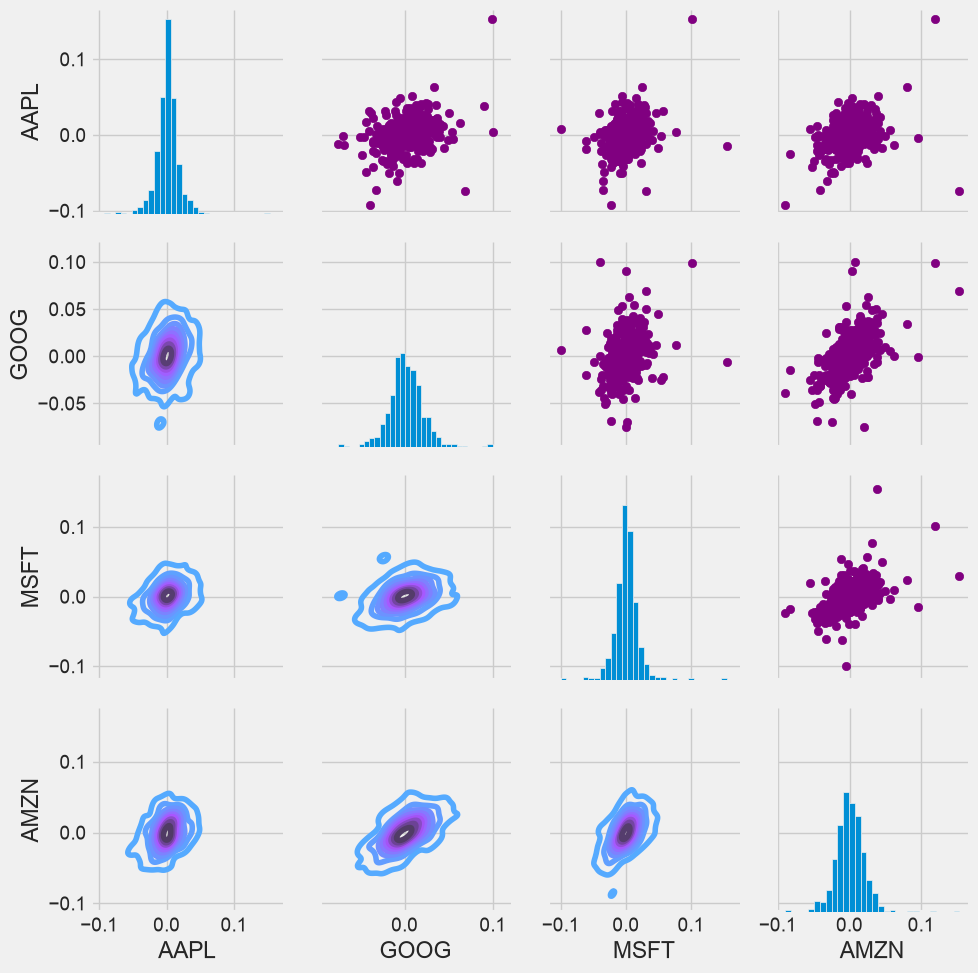

In [27]:
return_fig = sns.PairGrid(tech_rets.dropna())
return_fig.map_upper(plt.scatter, color='purple')
return_fig.map_lower(sns.kdeplot, cmap='cool_d')

return_fig.map_diag(plt.hist, bins=30)
plt.show()

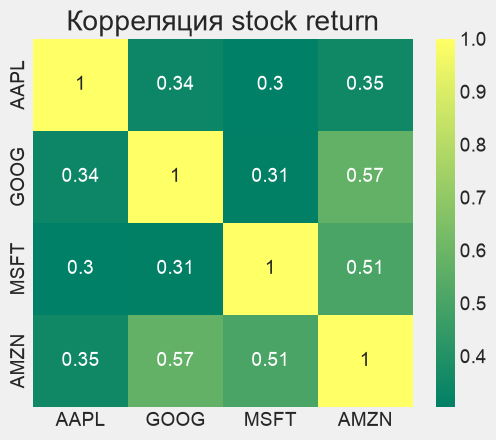

In [28]:
plt.figure(figsize=(12, 10))
plt.subplot(2,2,1)
sns.heatmap(tech_rets.corr(), annot=True, cmap='summer')
plt.title('Корреляция stock return')
plt.show()

#### Предсказание данных цены закртия для компании Apple

In [29]:
price_df = yf.download('AAPL', start='2012-01-01', end=datetime.now(),
                       auto_adjust=False, progress=False, multi_level_index=False)
if isinstance(price_df.columns, pd.MultiIndex):
            price_df.columns = price_df.columns.get_level_values(0)
if price_df.empty:
    raise RuntimeError('Ошибка загрузки данных')
price_df = price_df.sort_index()
price_df.head(20)

/opt/homebrew/lib/python3.11/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/opt/homebrew/lib/python3.11/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/opt/homebrew/lib/python3.11/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.sort_index(inplace=True)
/opt/homebrew/lib/pyth

,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2012-01-03,12.299735,14.686786,14.732143,14.607143,14.621429,302220800
2012-01-04,12.365837,14.765714,14.810000,14.617143,14.642857,260022000
2012-01-05,12.503120,14.929643,14.948214,14.738214,14.819643,271269600
2012-01-06,12.633827,15.085714,15.098214,14.972143,14.991786,318292800
2012-01-09,12.613789,15.061786,15.276786,15.048214,15.196429,394024400
2012-01-10,12.658955,15.115714,15.214286,15.053571,15.211071,258196400
2012-01-11,12.638314,15.091071,15.101786,14.975357,15.095714,215084800
2012-01-12,12.603617,15.049643,15.103571,14.955357,15.081429,212587200
2012-01-13,12.556361,14.993214,15.016071,14.952143,14.989286,226021600


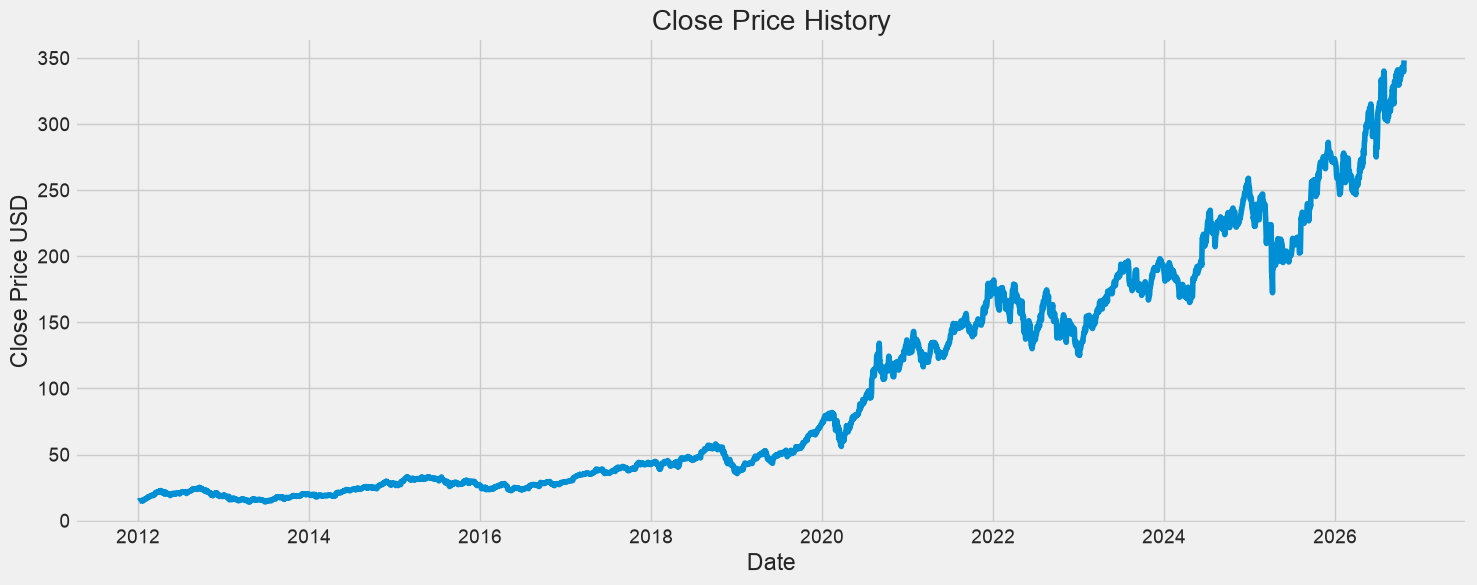

In [34]:
plt.figure(figsize=(16, 6))
plt.title('Close Price History')
plt.plot(price_df['Close'])
plt.xlabel('Date')
plt.ylabel('Close Price USD')
plt.show()

In [35]:
data = price_df[['Close']].copy()
dataset = data.to_numpy()
training_data_len = int(np.ceil(len(dataset)*0.95))
training_data_len

3537

In [36]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))
scaler.fit(dataset[:training_data_len])
scaled_data = scaler.transform(dataset)
scaled_data

array([[0.00271554],
       [0.00300546],
       [0.0036076 ],
       ...,
       [1.19581806],
       [1.21231067],
       [1.22784833]], shape=(3723, 1))

In [40]:
train_data = scaled_data[0:training_data_len, :]
x_train = []
y_train = []
for i in range(60, len(train_data)):
    x_train.append(train_data[i-60:i, 0])
    y_train.append(train_data[i, 0])

In [41]:
x_train[0]

array([0.00271554, 0.00300546, 0.0036076 , 0.00418088, 0.00409299,
       0.00429108, 0.00420056, 0.00404838, 0.00384111, 0.00448261,
       0.00506114, 0.00488273, 0.00390539, 0.00483812, 0.00391982,
       0.00736344, 0.00709714, 0.00744478, 0.00819647, 0.00865168,
       0.00861364, 0.00847327, 0.00907148, 0.00963426, 0.01027183,
       0.01130164, 0.01346489, 0.01349768, 0.01470197, 0.0156019 ,
       0.01405522, 0.0146508 , 0.014639  , 0.01630899, 0.01607154,
       0.01651101, 0.01730075, 0.01774023, 0.01900616, 0.01992839,
       0.0201947 , 0.02028785, 0.018711  , 0.01833056, 0.01838697,
       0.01986937, 0.02028654, 0.02118254, 0.02329462, 0.02611249,
       0.02558512, 0.02558643, 0.02762374, 0.02826131, 0.0278074 ,
       0.02739286, 0.02696126, 0.02839511, 0.02937901, 0.02979093])

In [42]:
y_train[0]

np.float64(0.02877292760128025)

In [43]:
x_train, y_train = np.array(x_train), np.array(y_train)

#### Предсказание с использованием LSTM

In [46]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, LSTM

model = Sequential([
    Input(shape=(x_train.shape[1], 1)),
    LSTM(128, return_sequences=True),
    LSTM(32),
    Dense(25),
    Dense(1)
])

model.compile(optimizer='adam', loss='mean_squared_error')
model.fit(x_train, y_train, batch_size=32, epochs=3, verbose=1)

Epoch 1/3
109/109 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - loss: 0.0029
Epoch 2/3
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 2.9007e-04
Epoch 3/3
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 2.8659e-04


In [48]:
test_data = scaled_data[training_data_len - 60:]
x_test = np.array([test_data[i-60:i, 0] for i in range(60, len(test_data))])
x_test = x_test.reshape(x_test.shape[0], x_test.shape[1], 1)
y_test = dataset[training_data_len:]
predictions = scaler.inverse_transform(model.predict(x_test))

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step


In [49]:
predictions

array([[247.11652],
       [247.00555],
       [247.20908],
       [247.6705 ],
       [248.8312 ],
       [250.35657],
       [252.4128 ],
       [254.66818],
       [257.0428 ],
       [259.16806],
       [260.95166],
       [262.4939 ],
       [263.05188],
       [262.61588],
       [261.96664],
       [261.2267 ],
       [260.28012],
       [259.47476],
       [258.8963 ],
       [258.8245 ],
       [259.20767],
       [259.8105 ],
       [260.06427],
       [260.10178],
       [259.9299 ],
       [259.55884],
       [258.95706],
       [258.0869 ],
       [257.21722],
       [256.4455 ],
       [255.78555],
       [254.97453],
       [253.81549],
       [252.63335],
       [251.57025],
       [250.42082],
       [249.23303],
       [248.03471],
       [247.08221],
       [246.35379],
       [245.87175],
       [245.5968 ],
       [245.2593 ],
       [244.78455],
       [244.61905],
       [244.75879],
       [245.1133 ],
       [245.74896],
       [246.25055],
       [246.92154],


In [50]:
rmse = np.sqrt(np.mean((predictions - y_test) ** 2))
rmse

np.float64(15.860221031798893)

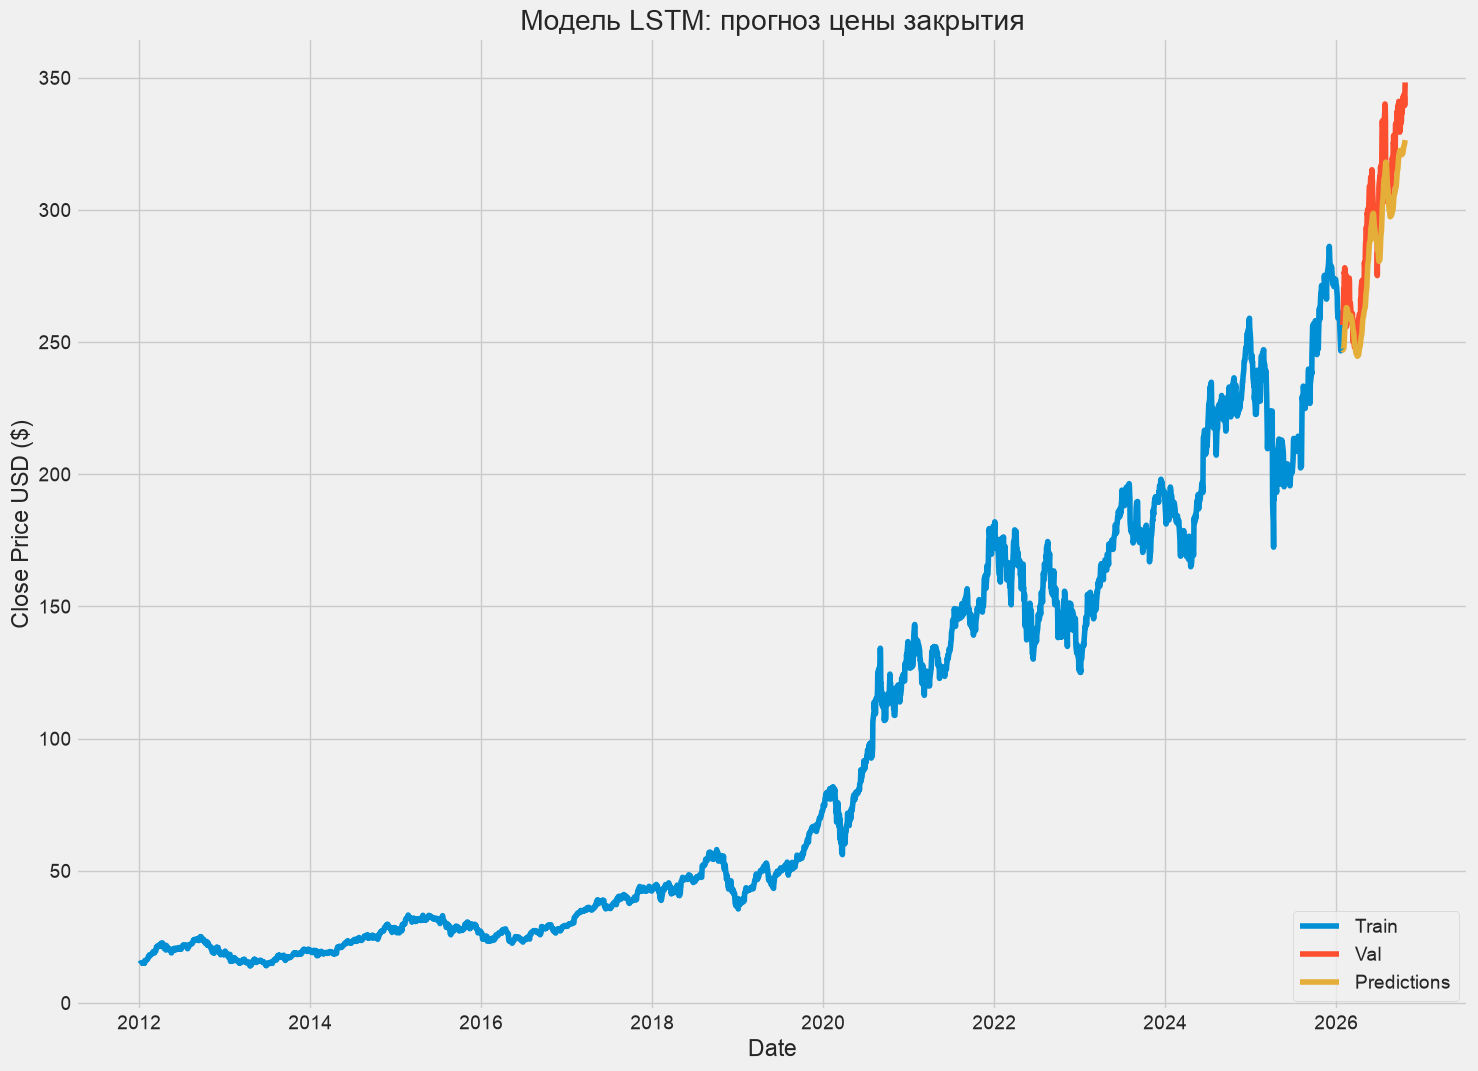

In [52]:
train = data.iloc[:training_data_len].copy()
valid = data.iloc[training_data_len:].copy()
valid['Predictions'] = predictions.ravel()
plt.figure(figsize=(16, 12))
plt.title('Модель LSTM: прогноз цены закрытия')
plt.xlabel('Date')
plt.ylabel('Close Price USD ($)')
plt.plot(train.index, train['Close'], label='Train')
plt.plot(valid.index, valid['Close'], label='Val')
plt.plot(valid.index, valid['Predictions'], label='Predictions')
plt.legend(loc='lower right')
plt.show()